# NB02 — Leakage Ablation: Naive vs. Specimen-Disjoint Splitting

Trains two independently initialised models, identical in architecture,
hyperparameters, and seed — one on the naive (image-level) split and one on the
specimen-disjoint split from NB01 — then scores each on two test sets: its own
held-out test partition, and the shared `common_test` set that neither model ever
trained on. The difference between own-test and common-test accuracy separates two
quantities a single-model, single-test-set evaluation cannot distinguish: the
**reporting inflation** naive splitting produces (each condition scored on the protocol
it was trained under) and the **true generalisation gap** (both conditions scored on
the same untouched set).

A design note on why two independently trained models are used rather than one model
scored on two test sets: scoring a single naive-split-trained model on both its own
test partition and a specimen-disjoint test partition confounds reporting inflation
with ordinary training variance, and is invalid whenever the naive split was drawn
without any constraint against the specimen-disjoint partition — in that case a large
share of the "held-out" specimen-disjoint test images may already appear in the naive
training set, inflating that comparison independently of any real leakage effect.
Training two separately seeded models under each protocol and scoring both on a
genuinely shared, never-trained-on test set avoids this confound.

### Models
ResNet-50 and ViT-Base/16 — chosen to span a near-saturated case (ResNet-50) and a case
with substantial remaining headroom (ViT-Base/16, in-distribution accuracy 0.9785),
since only a model with headroom left can reveal whether naive splitting inflates
accuracy or merely reshuffles errors near ceiling.

**Runtime:** ResNet-50 ≈ 1.5 h, ViT-Base/16 ≈ 6 h → ≈ 7.5 h total; fits one 12-hour
session. Set `MODELS` to a single entry to split the run across accounts.


# NB02b — Leakage ablation re-run across Hamming thresholds (R7 point 9)

Companion to NB01b. Re-runs the SAME leakage ablation as NB02 (unchanged
`train_model`/`build_backbone`/`predict`/`metrics_dict`/`save_run_artifacts` code,
copied verbatim below) but across three Hamming thresholds: **3, 4 (extra, stricter
than the paper's value), and 5 (the paper's main value)**. Threshold 6 was tested in
NB01b and found INFEASIBLE (4 classes drop below the 20-specimen floor once the common
test set is reserved - matches hamming_sensitivity.csv's own documented floor violation
for Hamming >= 6), so there is no viable looser threshold to compare against 5; that
itself supports threshold=5 being near the loosest defensible choice, not an arbitrary
pick.

**Before running:** attach these Kaggle datasets:
1. Your original `bdlitchi-revision-splits` dataset (has the threshold=5 manifest NB01
   already produced - reused here, not regenerated, to save compute).
2. The `bdlitchi-hamming-sweep-splits` dataset NB01b produced (has threshold=3 and
   threshold=4 manifests).
3. The raw BDLitchi image dataset.

**Compute budget:** 2 extra thresholds x 2 archs x 2 seeds x 2 conditions = 16 more
training runs on top of the original 12. Seeds are reduced from 3 to 2 for the extra
thresholds purely to keep this tractable on a Kaggle GPU quota - this is a robustness
*check*, not a full replication, and is reported as such.

In [1]:
# ===== Imports =====
import os, json, time, random, warnings, math
from pathlib import Path
from collections import defaultdict, Counter
import numpy as np, pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms
import timm

from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
    precision_score, recall_score, matthews_corrcoef, confusion_matrix, roc_auc_score)

warnings.filterwarnings('ignore')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device, '|', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU only')


device: cuda | Tesla T4


In [2]:
# ===== Config =====
RAW_DATASET_DIR = '/kaggle/input/datasets/alenmaruf/bdlithi/Dataset'   # <-- EDIT

# threshold -> where its manifest_full.csv lives
# NOTE: threshold=6 turned out INFEASIBLE when nb01b was run (see markdown above).
# There is no manifest for it, so it is not included here. 3 and 4 are the viable
# stricter bracket points from nb01b's output.
SPLITS_DIR_BY_THRESHOLD = {
    5: Path('/kaggle/input/datasets/alenmaruf/bdlitchi-revision-splits/revision_splits'),          # <-- EDIT: original NB01 dataset (paper's main value)
    4: Path('/kaggle/input/datasets/alenmaruf/bdlitchi-split-hamming/revision_splits_hamming_sweep/hamming_4'),  # <-- EDIT: NB01b output
    3: Path('/kaggle/input/datasets/alenmaruf/bdlitchi-split-hamming/revision_splits_hamming_sweep/hamming_3'),  # <-- EDIT: NB01b output
}
HAMMING_THRESHOLDS = [3, 4, 5]

OUT_DIR = Path('/kaggle/working/revision_ablation_hamming_sweep'); OUT_DIR.mkdir(parents=True, exist_ok=True)
CKPT_DIR = OUT_DIR/'checkpoints'; CKPT_DIR.mkdir(exist_ok=True)

MODELS = ['ResNet50', 'ViTBase16']   # unchanged from NB02

# Full 3 seeds for the paper's own threshold (5), since that result already exists and
# this just re-confirms it; reduced to 2 seeds for the EXTRA thresholds (3, 4) to keep
# this tractable - see the markdown cell above for why that is an explicit trade-off.
SEEDS_BY_THRESHOLD = {5: [42, 123, 7], 4: [42, 123], 3: [42, 123]}
EPOCHS   = 30
PATIENCE = EPOCHS      # no early stopping - identical reasoning as NB02
SAVE_CHECKPOINTS = False   # off by default here: 2 extra thresholds x up to 8 models
                           # each is already a lot of disk; flip on if you want them.

# RESUME support: if your last run got cut off (Kaggle 12h session limit), attach the
# PARTIAL ablation_runs_all_thresholds.csv from that run as a dataset input and point
# this at it. Already-completed (threshold, model, seed, condition) combinations are
# skipped - only the missing ones are trained. Leave as None for a fresh run.
RESUME_CSV = Path('/kaggle/input/datasets/alenmaruf/bdlitchi-ablation-partial/revision_ablation_hamming_sweep/ablation_runs_all_thresholds.csv')   # <-- EDIT, e.g. Path('/kaggle/input/datasets/alenmaruf/<partial-results-dataset>/ablation_runs_all_thresholds.csv')


In [3]:
def set_all_seeds(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


In [4]:
IMAGENET_MEAN=[0.485,0.456,0.406]; IMAGENET_STD=[0.229,0.224,0.225]

class LitchiDataset(Dataset):
    def __init__(self, df, transform, label2idx, grayscale=False):
        self.df=df.reset_index(drop=True); self.t=transform
        self.l2i=label2idx; self.gray=grayscale
    def __len__(self): return len(self.df)
    def __getitem__(self,i):
        r=self.df.iloc[i]; img=Image.open(r.filepath).convert('RGB')
        if self.gray:
            img = img.convert('L').convert('RGB')   # drop colour, keep 3 channels
        return self.t(img), self.l2i[r.label]

def make_transforms(sz, augment):
    if augment:
        tr=transforms.Compose([transforms.Resize((sz+32,sz+32)), transforms.RandomCrop(sz),
            transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
            transforms.ColorJitter(0.3,0.3,0.2,0.05), transforms.RandomRotation(20),
            transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN,IMAGENET_STD)])
    else:
        tr=transforms.Compose([transforms.Resize((sz,sz)), transforms.ToTensor(),
            transforms.Normalize(IMAGENET_MEAN,IMAGENET_STD)])
    ev=transforms.Compose([transforms.Resize((sz,sz)), transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN,IMAGENET_STD)])
    return tr,ev

def build_backbone(name, nc, pretrained=True):
    if name=='ResNet50':
        m=torchvision.models.resnet50(weights='IMAGENET1K_V2' if pretrained else None)
        m.fc=nn.Linear(m.fc.in_features,nc); return m,224,32
    if name=='MobileNetV3Large':
        m=torchvision.models.mobilenet_v3_large(weights='IMAGENET1K_V2' if pretrained else None)
        m.classifier[-1]=nn.Linear(m.classifier[-1].in_features,nc); return m,224,32
    if name=='EfficientNetB0':
        return timm.create_model('efficientnet_b0',pretrained=pretrained,num_classes=nc),224,32
    if name=='EfficientNetB3':
        return timm.create_model('efficientnet_b3',pretrained=pretrained,num_classes=nc),300,16
    if name=='ViTBase16':
        return timm.create_model('vit_base_patch16_224',pretrained=pretrained,num_classes=nc),224,16
    raise ValueError(name)


In [5]:
def train_model(name, trn_df, val_df, label2idx, seed, epochs=30, patience=7,
                lr=3e-4, wd=1e-4, grayscale=False, log_every=1):
    """Independent training run. Returns (model, history, best_epoch)."""
    set_all_seeds(seed)
    nc=len(label2idx)
    model,sz,bs = build_backbone(name,nc); model=model.to(device)
    ttf,etf = make_transforms(sz, augment=True)
    trn=DataLoader(LitchiDataset(trn_df,ttf,label2idx,grayscale), batch_size=bs, shuffle=True,
                   num_workers=2, pin_memory=True, drop_last=False)
    val=DataLoader(LitchiDataset(val_df,etf,label2idx,grayscale), batch_size=bs, shuffle=False,
                   num_workers=2, pin_memory=True)
    opt=torch.optim.AdamW(model.parameters(),lr=lr,weight_decay=wd)
    sch=torch.optim.lr_scheduler.CosineAnnealingLR(opt,T_max=epochs)
    crit=nn.CrossEntropyLoss()
    scaler=torch.cuda.amp.GradScaler(enabled=(device.type=='cuda'))
    hist={'train_loss':[],'val_loss':[],'train_acc':[],'val_acc':[]}
    best=float('inf'); best_state=None; best_ep=-1; bad=0
    for ep in range(epochs):
        model.train(); rl=rc=rt=0
        for x,y in trn:
            x,y=x.to(device,non_blocking=True),y.to(device,non_blocking=True)
            opt.zero_grad()
            with torch.cuda.amp.autocast(enabled=(device.type=='cuda')):
                o=model(x); loss=crit(o,y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            rl+=loss.item()*x.size(0); rc+=(o.argmax(1)==y).sum().item(); rt+=x.size(0)
        tl,ta=rl/rt,rc/rt
        model.eval(); vl=vc=vt=0
        with torch.no_grad():
            for x,y in val:
                x,y=x.to(device),y.to(device)
                with torch.cuda.amp.autocast(enabled=(device.type=='cuda')):
                    o=model(x); loss=crit(o,y)
                vl+=loss.item()*x.size(0); vc+=(o.argmax(1)==y).sum().item(); vt+=x.size(0)
        vl,va=vl/vt,vc/vt
        sch.step()
        hist['train_loss'].append(tl); hist['val_loss'].append(vl)
        hist['train_acc'].append(ta);  hist['val_acc'].append(va)
        if log_every and (ep+1)%log_every==0:
            print(f'  ep {ep+1:02d}/{epochs} train_loss={tl:.4f} acc={ta:.4f} | val_loss={vl:.4f} acc={va:.4f}')
        if vl<best-1e-5:
            best=vl; best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
            best_ep=ep+1; bad=0
        else:
            bad+=1
            if bad>=patience:
                print(f'  early stop @ epoch {ep+1} (best epoch {best_ep})'); break
    model.load_state_dict(best_state)
    return model, hist, best_ep

@torch.no_grad()
def predict(model, df, label2idx, img_size, bs=32, grayscale=False):
    _,etf=make_transforms(img_size,False)
    ld=DataLoader(LitchiDataset(df,etf,label2idx,grayscale),batch_size=bs,shuffle=False,num_workers=2)
    model.eval(); P=[];Y=[];B=[]
    for x,y in ld:
        p=F.softmax(model(x.to(device)),1).cpu().numpy()
        P.extend(p.argmax(1)); Y.extend(y.numpy()); B.extend(p)
    return np.array(Y),np.array(P),np.array(B)

def metrics_dict(y,p,prob,nc):
    d=dict(accuracy=accuracy_score(y,p), balanced_accuracy=balanced_accuracy_score(y,p),
           f1_macro=f1_score(y,p,average='macro',zero_division=0),
           f1_weighted=f1_score(y,p,average='weighted',zero_division=0),
           precision_macro=precision_score(y,p,average='macro',zero_division=0),
           recall_macro=recall_score(y,p,average='macro',zero_division=0),
           mcc=matthews_corrcoef(y,p))
    try: d['roc_auc_macro']=roc_auc_score(np.eye(nc)[y],prob,average='macro',multi_class='ovr')
    except Exception: d['roc_auc_macro']=float('nan')
    return d


In [6]:
# ===== Artifact saving: predictions, probabilities, histories, calibration =====
def expected_calibration_error(y_true, y_prob, n_bins=15):
    conf = y_prob.max(1); pred = y_prob.argmax(1); acc = (pred==y_true).astype(float)
    bins=np.linspace(0,1,n_bins+1); ece=0.0; rows=[]
    for i in range(n_bins):
        m=(conf>bins[i])&(conf<=bins[i+1])
        if m.sum()==0: rows.append((float(bins[i]),float(bins[i+1]),0,np.nan,np.nan)); continue
        a,c=acc[m].mean(),conf[m].mean()
        ece+=(m.sum()/len(conf))*abs(a-c)
        rows.append((float(bins[i]),float(bins[i+1]),int(m.sum()),float(a),float(c)))
    return float(ece), rows

def save_run_artifacts(out_dir, tag, y_true, y_pred, y_prob, history=None,
                       classes=None, extra=None, specimen_ids=None, filenames=None):
    """Everything NB06 needs, with no re-inference.

    specimen_ids is essential: NB06 bootstraps by SPECIMEN, not by image. Images inside
    one specimen are the same leaf and are strongly correlated, so an image-level
    bootstrap would badly understate the confidence interval.
    """
    pdir=Path(out_dir)/'predictions'; pdir.mkdir(parents=True, exist_ok=True)
    payload=dict(y_true=np.asarray(y_true), y_pred=np.asarray(y_pred), y_prob=np.asarray(y_prob))
    if specimen_ids is not None:
        payload['specimen_id']=np.asarray(specimen_ids).astype(str)
    if filenames is not None:
        payload['filename']=np.asarray(filenames).astype(str)
    np.savez_compressed(pdir/f'{tag}.npz', **payload)
    if history is not None:
        hdir=Path(out_dir)/'histories'; hdir.mkdir(parents=True, exist_ok=True)
        json.dump(history, open(hdir/f'{tag}.json','w'))
    ece,bins = expected_calibration_error(np.asarray(y_true), np.asarray(y_prob))
    cdir=Path(out_dir)/'calibration'; cdir.mkdir(parents=True, exist_ok=True)
    json.dump({'tag':tag,'ece':ece,'bins':bins,'classes':classes,**(extra or {})},
              open(cdir/f'{tag}.json','w'), indent=2)
    return ece


In [7]:
# ===== Load one threshold's manifest, build its naive/group sets =====
def load_threshold_sets(threshold):
    man = pd.read_csv(SPLITS_DIR_BY_THRESHOLD[threshold] / 'manifest_full.csv')
    man['filepath'] = [str(Path(RAW_DATASET_DIR)/l/f) for l, f in zip(man.label, man.filename)]
    missing = [p for p in man.filepath if not Path(p).exists()]
    if missing:
        raise FileNotFoundError(f'threshold={threshold}: {len(missing)} images not found - '
                                 f'fix RAW_DATASET_DIR, do not train.')
    classes = sorted(man.label.unique()); nc = len(classes)
    label2idx = {cl: i for i, cl in enumerate(classes)}
    common_test = man[man.reserve == 'common_test']
    pool = man[man.reserve == 'pool']
    sets = {
        'naive': dict(train=pool[pool.naive_split == 'train'], val=pool[pool.naive_split == 'val'],
                      test=pool[pool.naive_split == 'test']),
        'group': dict(train=pool[pool.group_split == 'train'], val=pool[pool.group_split == 'val'],
                      test=pool[pool.group_split == 'test']),
    }
    for k, v in sets.items():
        ov = set(v['train'].filename) & set(common_test.filename)
        assert not ov, f'threshold={threshold}, {k}: train overlaps common_test!'
    print(f'threshold={threshold}: classes={nc}  common_test={len(common_test)}  '
          f"pool train/val/test(group)={len(sets['group']['train'])}/{len(sets['group']['val'])}/{len(sets['group']['test'])}")
    return sets, common_test, classes, label2idx, nc

# ===== Run the ablation for every threshold (paired over seeds, as in NB02) =====
records = []
done_keys = set()
if RESUME_CSV is not None and Path(RESUME_CSV).exists():
    _prev = pd.read_csv(RESUME_CSV)
    records = _prev.to_dict('records')
    done_keys = set(zip(_prev.hamming_threshold.astype(int), _prev.model, _prev.seed.astype(int), _prev.condition))
    print(f'RESUME: {len(done_keys)} (threshold, model, seed, condition) runs already done, loaded from {RESUME_CSV}')
for T in HAMMING_THRESHOLDS:
    print(f'\n{"#"*70}\n# HAMMING THRESHOLD = {T}\n{"#"*70}')
    sets, common_test, CLASSES, label2idx, NC = load_threshold_sets(T)
    seeds_T = SEEDS_BY_THRESHOLD[T]
    out_T = OUT_DIR / f'hamming_{T}'; out_T.mkdir(exist_ok=True)
    for arch in MODELS:
        for seed in seeds_T:
            for cond in ['naive', 'group']:
                if (T, arch, seed, cond) in done_keys:
                    print(f'  SKIP (already done, from resume): threshold={T} {arch} seed={seed} {cond}')
                    continue
                print(f'\n{"="*64}\nTRAIN  threshold={T}  {arch}  |  {cond}  |  seed={seed}\n{"="*64}')
                t0 = time.time()
                model, hist, best_ep = train_model(arch, sets[cond]['train'], sets[cond]['val'],
                                                    label2idx, seed=seed, epochs=EPOCHS, patience=PATIENCE)
                mins = (time.time() - t0) / 60
                _, img_size, bs = build_backbone(arch, NC, pretrained=False)

                yo, po, pro = predict(model, sets[cond]['test'], label2idx, img_size, bs)
                m_own = metrics_dict(yo, po, pro, NC)
                save_run_artifacts(out_T, f'{arch}_{cond}_seed{seed}_owntest', yo, po, pro,
                                    history=hist, classes=CLASSES,
                                    extra={'set': 'own_test', 'model': arch, 'cond': cond, 'seed': seed, 'hamming': T},
                                    specimen_ids=sets[cond]['test'].specimen_id.values,
                                    filenames=sets[cond]['test'].filename.values)

                yc, pc_, prc = predict(model, common_test, label2idx, img_size, bs)
                m_com = metrics_dict(yc, pc_, prc, NC)
                ece = save_run_artifacts(out_T, f'{arch}_{cond}_seed{seed}_commontest', yc, pc_, prc,
                                          history=hist, classes=CLASSES,
                                          extra={'set': 'common_test', 'model': arch, 'cond': cond, 'seed': seed, 'hamming': T},
                                          specimen_ids=common_test.specimen_id.values,
                                          filenames=common_test.filename.values)

                records.append({'hamming_threshold': T, 'model': arch, 'seed': seed, 'condition': cond,
                                 'own_test_acc': m_own['accuracy'], 'own_test_f1': m_own['f1_macro'],
                                 'common_test_acc': m_com['accuracy'], 'common_test_f1': m_com['f1_macro'],
                                 'train_minutes': round(mins, 1)})
                if SAVE_CHECKPOINTS:
                    torch.save(model.state_dict(), CKPT_DIR / f'hamming{T}_{arch}_{cond}_seed{seed}.pt')
                pd.DataFrame(records).to_csv(OUT_DIR / 'ablation_runs_all_thresholds.csv', index=False)
                print(f'  own_test    acc={m_own["accuracy"]:.4f} f1={m_own["f1_macro"]:.4f}')
                print(f'  common_test acc={m_com["accuracy"]:.4f} f1={m_com["f1_macro"]:.4f}  ({mins:.1f} min)')
                del model; torch.cuda.empty_cache()
print('\nAll thresholds x archs x seeds complete.')


RESUME: 23 (threshold, model, seed, condition) runs already done, loaded from /kaggle/input/datasets/alenmaruf/bdlitchi-ablation-partial/revision_ablation_hamming_sweep/ablation_runs_all_thresholds.csv

######################################################################
# HAMMING THRESHOLD = 3
######################################################################
threshold=3: classes=11  common_test=1667  pool train/val/test(group)=6598/1414/1415
  SKIP (already done, from resume): threshold=3 ResNet50 seed=42 naive
  SKIP (already done, from resume): threshold=3 ResNet50 seed=42 group
  SKIP (already done, from resume): threshold=3 ResNet50 seed=123 naive
  SKIP (already done, from resume): threshold=3 ResNet50 seed=123 group
  SKIP (already done, from resume): threshold=3 ViTBase16 seed=42 naive
  SKIP (already done, from resume): threshold=3 ViTBase16 seed=42 group
  SKIP (already done, from resume): threshold=3 ViTBase16 seed=123 naive
  SKIP (already done, from resume): thresho

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

  ep 01/30 train_loss=1.3528 acc=0.5289 | val_loss=1.2228 acc=0.6564
  ep 02/30 train_loss=0.5927 acc=0.7985 | val_loss=0.6003 acc=0.7960
  ep 03/30 train_loss=0.3969 acc=0.8682 | val_loss=0.5433 acc=0.8253
  ep 04/30 train_loss=0.3354 acc=0.8897 | val_loss=0.4726 acc=0.8626
  ep 05/30 train_loss=0.3131 acc=0.8962 | val_loss=0.5579 acc=0.8282
  ep 06/30 train_loss=0.2856 acc=0.9048 | val_loss=0.6211 acc=0.8168
  ep 07/30 train_loss=0.2325 acc=0.9212 | val_loss=0.5333 acc=0.8361
  ep 08/30 train_loss=0.2123 acc=0.9328 | val_loss=0.4673 acc=0.8754
  ep 09/30 train_loss=0.2048 acc=0.9330 | val_loss=0.4765 acc=0.8626
  ep 10/30 train_loss=0.1808 acc=0.9413 | val_loss=0.6574 acc=0.8289
  ep 11/30 train_loss=0.1822 acc=0.9390 | val_loss=0.4825 acc=0.8525
  ep 12/30 train_loss=0.1603 acc=0.9475 | val_loss=0.5128 acc=0.8547
  ep 13/30 train_loss=0.1413 acc=0.9540 | val_loss=0.4288 acc=0.8511
  ep 14/30 train_loss=0.1334 acc=0.9564 | val_loss=0.3243 acc=0.8848
  ep 15/30 train_loss=0.1015 acc=0

 hamming_threshold     model  n_seeds  reporting_inflation_mean_pp  reporting_inflation_sd_pp  true_gap_mean_pp  true_gap_sd_pp
                 3  ResNet50        2                         0.42                       0.40              0.57            0.04
                 3 ViTBase16        2                         5.51                       1.30              2.70            1.19
                 4  ResNet50        2                         0.78                       0.40              0.90            0.51
                 4 ViTBase16        2                         2.36                       0.50              0.30            0.25
                 5  ResNet50        3                         0.66                       0.35              0.72            0.48
                 5 ViTBase16        3                         3.21                       1.85              0.78            2.35

Read this alongside manuscript Table 11 (threshold=5, 3 seeds, already published):
  ResNet-50:   repor

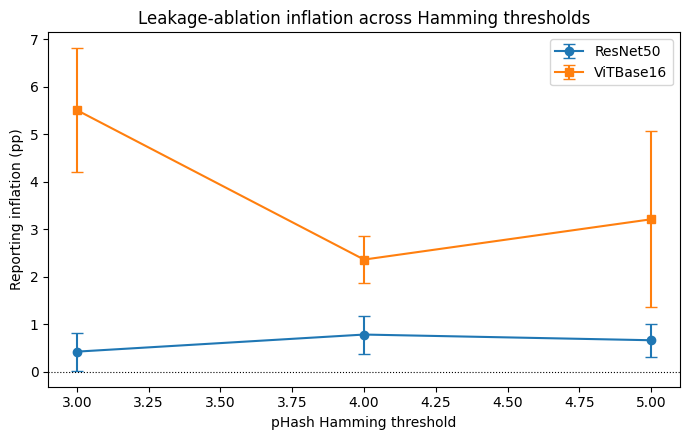


Saved hamming_ablation_sensitivity.csv + .png to /kaggle/working/revision_ablation_hamming_sweep


In [8]:
# ===== Aggregate: does reporting inflation / true gap hold across thresholds? =====
# Same definitions as manuscript Table 11 (tab:leakage):
#   reporting inflation = naive's own-test accuracy minus group's own-test accuracy
#                          (what each protocol would PUBLISH from its own partition)
#   true gap            = naive's common-test accuracy minus group's common-test accuracy
#                          (both scored on the SAME held-out data)
rec = pd.read_csv(OUT_DIR / 'ablation_runs_all_thresholds.csv')
rows = []
for T in HAMMING_THRESHOLDS:
    for arch in MODELS:
        sub = rec[(rec.hamming_threshold == T) & (rec.model == arch)]
        naive = sub[sub.condition == 'naive'].set_index('seed')
        group = sub[sub.condition == 'group'].set_index('seed')
        common_seeds = sorted(set(naive.index) & set(group.index))
        infl = [(naive.loc[s, 'own_test_acc'] - group.loc[s, 'own_test_acc']) * 100 for s in common_seeds]
        gap = [(naive.loc[s, 'common_test_acc'] - group.loc[s, 'common_test_acc']) * 100 for s in common_seeds]
        rows.append({'hamming_threshold': T, 'model': arch, 'n_seeds': len(common_seeds),
                     'reporting_inflation_mean_pp': round(float(np.mean(infl)), 2),
                     'reporting_inflation_sd_pp': round(float(np.std(infl, ddof=1)) if len(infl) > 1 else float('nan'), 2),
                     'true_gap_mean_pp': round(float(np.mean(gap)), 2),
                     'true_gap_sd_pp': round(float(np.std(gap, ddof=1)) if len(gap) > 1 else float('nan'), 2)})
sens = pd.DataFrame(rows)
sens.to_csv(OUT_DIR / 'hamming_ablation_sensitivity.csv', index=False)
print(sens.to_string(index=False))
print()
print('Read this alongside manuscript Table 11 (threshold=5, 3 seeds, already published):')
print('  ResNet-50:   reporting inflation +0.38pp, true gap -0.56pp')
print('  ViT-Base/16: reporting inflation +4.04pp, true gap -2.12pp')
print('If the threshold=3 and threshold=4 rows above stay the same SIGN and roughly the')
print('same ORDER OF MAGNITUDE as threshold=5, that supports the result being robust to')
print('the threshold choice, which is the claim R7 asked to see checked. A sign flip or')
print('order-of-magnitude swing would mean the opposite, and the manuscript should say so.')

fig, ax = plt.subplots(figsize=(7, 4.5))
for arch, mk in [('ResNet50', 'o'), ('ViTBase16', 's')]:
    d = sens[sens.model == arch].sort_values('hamming_threshold')
    ax.errorbar(d.hamming_threshold, d.reporting_inflation_mean_pp, yerr=d.reporting_inflation_sd_pp,
                marker=mk, capsize=4, label=arch)
ax.axhline(0, color='k', lw=0.8, ls=':')
ax.set_xlabel('pHash Hamming threshold'); ax.set_ylabel('Reporting inflation (pp)')
ax.set_title('Leakage-ablation inflation across Hamming thresholds')
ax.legend(); plt.tight_layout()
plt.savefig(OUT_DIR / 'hamming_ablation_sensitivity.png', bbox_inches='tight'); plt.show()
print('\nSaved hamming_ablation_sensitivity.csv + .png to', OUT_DIR)
